In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors, cm
from scipy.stats import pearsonr

import glob

from dataclasses import dataclass
from collections import defaultdict
import pathlib
import os
import signac

from monk import utils, workflow
from tqdm.notebook import tqdm

In [2]:
qle_files = glob.glob("/media/ian/Poppy/improved-nn/qle-v2/*/*.npz")

keep_files = []
for file in qle_files:
    data = np.load(file)
    if np.mean(data["f16"]) < 1.0:
        keep_files.append(file)

qle_files = keep_files

In [3]:
d2min_files = [file.replace("qle", "d2min").replace("npz", "parquet").replace("-v2", "-v1") for file in qle_files]

In [4]:
d2min_files[0]

'/media/ian/Poppy/improved-nn/d2min-v1/6976a7c10ada4159010403f8027f3ea5/dataset_max-shear-0.08_period-1000.0_temp-0.0496_frame-519.parquet'

In [5]:
@dataclass(frozen=True, eq=True)
class Statepoint:
    max_shear: float
    period: float
    temp: float
    prep: str
    cycle: int

In [6]:
idx = 0
qle_data = np.load(qle_files[idx])
d2min_data = pd.read_parquet(d2min_files[idx])

pr = pearsonr(qle_data["f512"], d2min_data["d2min_rev"])
pr

PearsonRResult(statistic=0.006401182829526446, pvalue=0.2465762351832438)

In [7]:
cwd = pathlib.Path(os.getcwd())
parent = cwd.parent.parent / "config.yaml"
config = workflow.get_config(parent.as_posix())

In [8]:
project: signac.Project = signac.get_project(root=config['root'])
project.doc

{'avail_seed': 18, 'dt': 0.005, 'step_unit': 200, 'equil_time': 100, 'min_periods': 20, 'dumps': 40, 'period_times': [30.0, 100.0, 300.0, 1000.0], 'max_shears': [0.01, 0.02, 0.03, 0.05, 0.08, 0.12, 0.04, 0.06, 0.07], '_status': {}}

In [9]:
prep_dict = {}
for job in project:
    prep = job.sp["prep"]
    if prep == "ESL":
        prep = "GQ"
    prep_dict[job.id] = prep

In [10]:
prep_dict

{'634e14bc75836df75158fb15f379d8bb': 'HTL',
 '7ec2f6aca035e69077eab24383a21cb6': 'GQ',
 'cfa1e4c0007fd65d020f809715a6f0b4': 'HTL',
 'ecce68c50e28a33684826f28780bf6e9': 'HTL',
 '1d0fe2ba44a6f635f5504dcbcee0ebc9': 'GQ',
 '1083a2a09eec2c6cf215ebc7a9706cac': 'HTL',
 '09d3dccc56f1fa9330b57901cd232ab7': 'GQ',
 '6976a7c10ada4159010403f8027f3ea5': 'HTL',
 '9158e73b2e4c9fd1a565e1e5d1bc3af5': 'HTL',
 'c6d7afd0de62bfa16d05da47815227eb': 'GQ',
 'bf92a185d043ce3ef666e05e427c7e76': 'GQ',
 'a8f2c249ed85533b56b0729b7ab96d18': 'GQ'}

In [11]:
output = defaultdict(list)
for idx in tqdm(range(len(qle_files))):
    exper = qle_files[idx]
    qle_data = np.load(exper)
    d2min_data = pd.read_parquet(d2min_files[idx])
    max_shear = utils.extract_between(exper, "max-shear-", "_")
    period = utils.extract_between(exper, "period-", "_")
    temp = utils.extract_between(exper, "temp-", "_")
    cycle = (int(utils.extract_between(exper, "frame-", ".")) + 1 ) // 40
    prep = prep_dict[exper.split("/")[-2]]
    sp = Statepoint(max_shear=float(max_shear), period=float(period), temp=float(temp), prep=prep, cycle=cycle)
    # if float(temp) > 1e-2:
    #     continue
    new_df = d2min_data[["soft", "d2min_irr", "d2min_rev", "d2min_left", "d2min_right"]]
    new_df["f512"] = qle_data["f512"]
    output[sp].append(new_df)
    # break

  0%|          | 0/1077 [00:00<?, ?it/s]

/tmp/ipykernel_340320/1673827923.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df["f512"] = qle_data["f512"]
/tmp/ipykernel_340320/1673827923.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df["f512"] = qle_data["f512"]
/tmp/ipykernel_340320/1673827923.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/

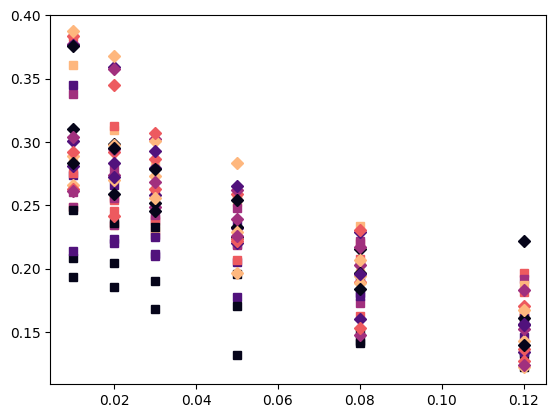

In [12]:
cmap = cm.magma
norm = colors.Normalize(vmin=0, vmax=20)

for key, val in output.items():

    df = pd.concat(val)

    if key.prep == "GQ":
        m = "D"
    else:
        m = "s"

    # if key.cycle == 1:
    #     c = "red"
    # else:
    #     c = "blue"
    c = cmap(norm(key.cycle))

    pr = pearsonr(np.log(df["f512"]), np.log(df["d2min_irr"]))
    plt.plot(key.max_shear, pr[0], marker=m, color=c)

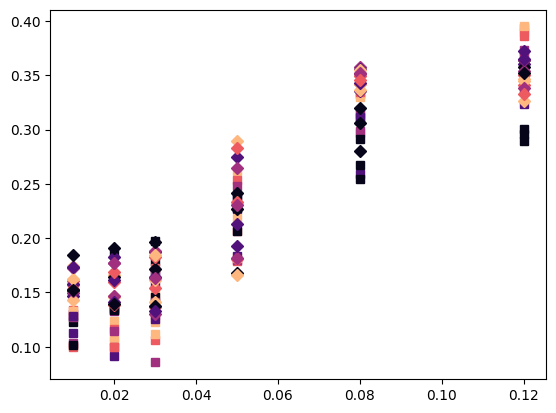

In [13]:
cmap = cm.magma
norm = colors.Normalize(vmin=0, vmax=20)

for key, val in output.items():

    df = pd.concat(val)

    if key.prep == "GQ":
        m = "D"
    else:
        m = "s"

    # if key.cycle == 1:
    #     c = "red"
    # else:
    #     c = "blue"
    c = cmap(norm(key.cycle))

    pr = pearsonr(df["soft"], np.log(df["d2min_irr"]))
    plt.plot(key.max_shear, pr[0], marker=m, color=c)

In [14]:
@dataclass(frozen=True, eq=True)
class Plot:
    prep: str
    cycle: int

In [15]:
import scipy.stats as stats

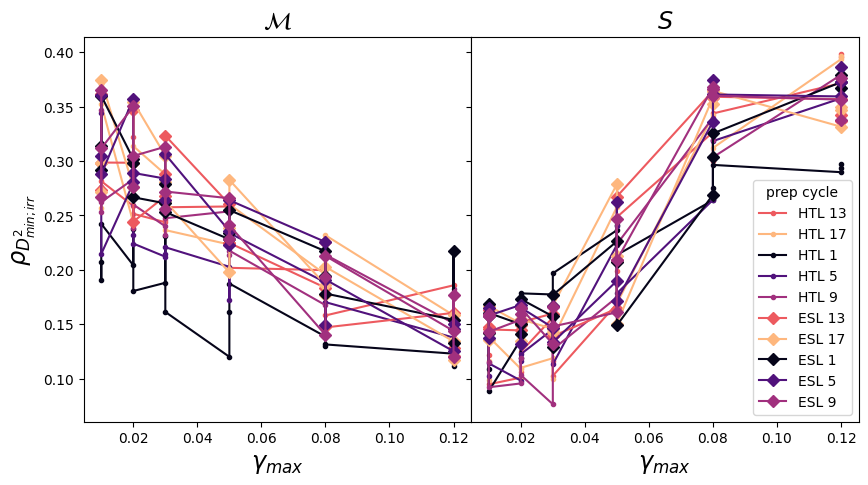

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

cmap = cm.magma
norm = colors.Normalize(vmin=0, vmax=20)

#remove padding be

d2min_name = "d2min_irr"

plot_out = defaultdict(list)

for key, val in output.items():

    df = pd.concat(val)

    pr = stats.spearmanr(np.log(df["f512"]), np.log(df[d2min_name]))
    plot_out[Plot(prep=key.prep, cycle=key.cycle)].append((key.max_shear, pr[0]))
    # plt.plot(key.max_shear, pr[0], marker=m, color=c)

plt.sca(axs[0])
plt.ylabel(r"$\rho_{D^2_{min;irr}}$", size="xx-large")
plt.xlabel(r"$\gamma_{max}$", size="xx-large")
plt.title(r"$\mathcal{M}$", size="xx-large")

for key, val in plot_out.items():
    if key.prep == "GQ":
        m = "D"
        
    else:
        m = "."
        # ls = ":"
    ls = "-"

    # if key.cycle == 1:
    #     c = "green"
    # else:
    #     c = "purple"
    c = cmap(norm(key.cycle))

    val = sorted(val, key=lambda x: x[0])
    x, y = zip(*val)
    plt.plot(x, y, marker=m, color=c, ls=ls)

plot_out = defaultdict(list)

for key, val in output.items():

    df = pd.concat(val)

    pr = stats.spearmanr((df["soft"]), np.log(df[d2min_name]))
    plot_out[Plot(prep=key.prep, cycle=key.cycle)].append((key.max_shear, pr[0]))
    # plt.plot(key.max_shear, pr[0], marker=m, color=c)

plt.sca(axs[1])
plt.title(r"$S$", size="xx-large")

for key, val in plot_out.items():
    if key.prep == "GQ":
        prep = "ESL"
        m = "D"
        # ls = "-"
    else:
        prep = "HTL"
        m = "."
    ls = "-"

    # if key.cycle == 1:
    #     c = "green"
    # else:
    #     c = "purple"
    c = cmap(norm(key.cycle))

    val = sorted(val, key=lambda x: x[0])
    x, y = zip(*val)
    plt.plot(x, y, marker=m, color=c, ls=ls, label=f"{prep} {key.cycle}")

# ax1 = plt.gca()

plt.legend(title="prep cycle")
# plt.axis('on')
# ax1.set_xticklabels([])
# ax1.set_yticklabels([])
# ax1.set_aspect('equal')
plt.subplots_adjust(wspace=0)

plt.xlabel(r"$\gamma_{max}$", size="xx-large")

plt.savefig("corr-irr-temps.png", dpi=200, bbox_inches="tight")

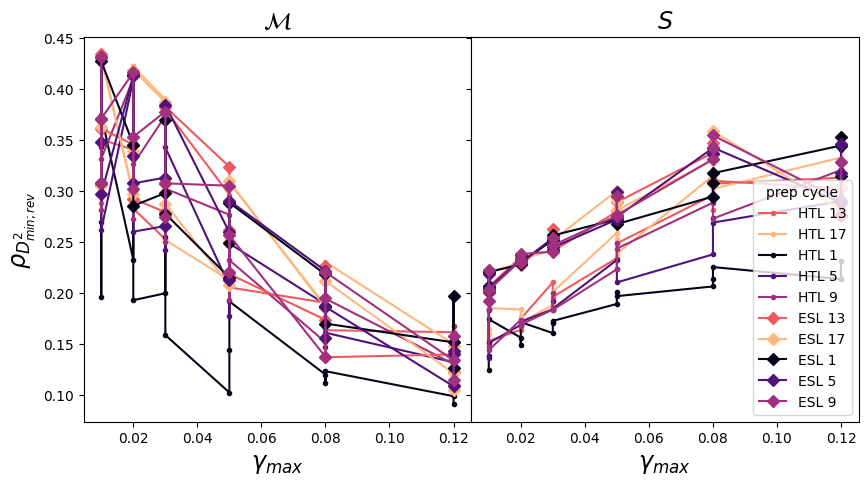

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)

cmap = cm.magma
norm = colors.Normalize(vmin=0, vmax=20)
#remove padding be

d2min_name = "d2min_rev"

plot_out = defaultdict(list)

for key, val in output.items():

    df = pd.concat(val)

    pr = stats.spearmanr(np.log(df["f512"]), np.log(df[d2min_name]))
    plot_out[Plot(prep=key.prep, cycle=key.cycle)].append((key.max_shear, pr[0]))
    # plt.plot(key.max_shear, pr[0], marker=m, color=c)

plt.sca(axs[0])
plt.ylabel(r"$\rho_{D^2_{min;rev}}$", size="xx-large")
plt.xlabel(r"$\gamma_{max}$", size="xx-large")
plt.title(r"$\mathcal{M}$", size="xx-large")

for key, val in plot_out.items():
    if key.prep == "GQ":
        m = "D"
        
    else:
        m = "."
        # ls = ":"
    ls = "-"

    # if key.cycle == 1:
    #     c = "green"
    # else:
    #     c = "purple"
    c = cmap(norm(key.cycle))

    val = sorted(val, key=lambda x: x[0])
    x, y = zip(*val)
    plt.plot(x, y, marker=m, color=c, ls=ls)

plot_out = defaultdict(list)

for key, val in output.items():

    df = pd.concat(val)

    pr = stats.spearmanr((df["soft"]), np.log(df[d2min_name]))
    plot_out[Plot(prep=key.prep, cycle=key.cycle)].append((key.max_shear, pr[0]))
    # plt.plot(key.max_shear, pr[0], marker=m, color=c)

plt.sca(axs[1])
plt.title(r"$S$", size="xx-large")

for key, val in plot_out.items():
    if key.prep == "GQ":
        prep = "ESL"
        m = "D"
        # ls = "-"
    else:
        prep = "HTL"
        m = "."
    ls = "-"

    # if key.cycle == 1:
    #     c = "green"
    # else:
    #     c = "purple"
    c = cmap(norm(key.cycle))

    val = sorted(val, key=lambda x: x[0])
    x, y = zip(*val)
    plt.plot(x, y, marker=m, color=c, ls=ls, label=f"{prep} {key.cycle}")

# ax1 = plt.gca()

plt.legend(title="prep cycle")
# plt.axis('on')
# ax1.set_xticklabels([])
# ax1.set_yticklabels([])
# ax1.set_aspect('equal')
plt.subplots_adjust(wspace=0)

plt.xlabel(r"$\gamma_{max}$", size="xx-large")

plt.savefig("corr-temps.png", dpi=200, bbox_inches="tight")

/tmp/ipykernel_3335188/2751059382.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for bin, tdf in df.groupby("bins"):
/tmp/ipykernel_3335188/2751059382.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for bin, tdf in df.groupby("bins"):
/tmp/ipykernel_3335188/2751059382.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for bin, tdf in df.groupby("bins"):
/tmp/ipykernel_3335188/2751059382.py:25: FutureWarning:

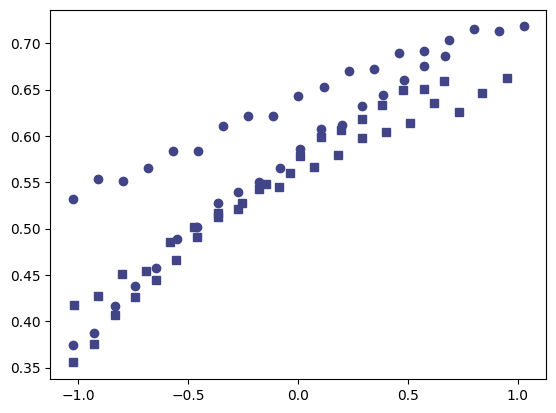

In [136]:
plot_out = defaultdict(list)

cmap = plt.get_cmap("viridis")
norm = colors.Normalize(vmin=0, vmax=.15)

for key, val in output.items():
    if key.max_shear != 0.03:
        continue

    df = pd.concat(val)

    if key.cycle == 1:
        m = "o"
    else:
        m = "s"

    # pr = pearsonr(np.log(df["f512"]), np.log(df["d2min_rev"]))
    # bins f512 and get rearrangement probability as a function of bin
    # logf = np.log(df["f512"])
    logf = df["soft"]
    q5 = np.quantile(logf, 0.05)
    q95 = np.quantile(logf, 0.95)
    bins = np.linspace(q5, q95, 20)
    df["bins"] = pd.cut(logf, bins)
    for bin, tdf in df.groupby("bins"):
        prob_rearrange = np.mean(tdf["d2min_rev"] > 0.08)
        
        plt.plot(bin.mid, prob_rearrange, marker=m, color=cmap(norm(key.max_shear)))
#     plot_out[Plot(prep=key.prep, cycle=key.cycle)].append((key.max_shear, pr[0]))
#     # plt.plot(key.max_shear, pr[0], marker=m, color=c)

# for key, val in plot_out.items():
#     if key.prep == "GQ":
#         m = "D"
        
#     else:
#         m = "s"
#         # ls = ":"
#     ls = "-"

#     if key.cycle == 1:
#         c = "red"
#     else:
#         c = "blue"

#     val = sorted(val, key=lambda x: x[0])
#     x, y = zip(*val)
#     plt.plot(x, y, marker=m, color=c, ls=ls)

In [1]:
plot_out = defaultdict(list)

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(12, 5))

cmap = plt.get_cmap("magma")
norm = colors.Normalize(vmin=-5, vmax=25)

plt.sca(axs[0])

for key, val in output.items():
    if key.max_shear != 0.08:
        continue

    df = pd.concat(val)
    # pr = pearsonr(np.log(df["f512"]), np.log(df["d2min_rev"]))
    # bins f512 and get rearrangement probability as a function of bin
    logf = np.log(df["f512"])
    # logf = df["soft"]
    q5 = np.quantile(logf, 0.01)
    q95 = np.quantile(logf, 0.99)
    bins = np.linspace(q5, q95, 20)
    df["bins"] = pd.cut(logf, bins)

    vals = []
    for bin, tdf in df.groupby("bins"):
        prob_rearrange = np.mean(tdf["d2min_rev"] > 0.08)
        
        # plt.plot(bin.mid, prob_rearrange, marker=m,
        # color=cmap(norm(key.max_shear)))
        vals.append((bin.mid, prob_rearrange))

    prep = key.prep
    if prep == "GQ":
        prep = "ESL"
        ls = "-"
    else:
        ls = ":"

    vals = sorted(vals, key=lambda x: x[0])

    x, y = zip(*vals)
    plt.plot(x, y, ls=ls, color=cmap(norm(key.cycle)), label=f"{prep} {key.cycle}")

# plt.legend(title=r"prep $t_{wait}$")
    
#     plot_out[Plot(prep=key.prep, cycle=key.cycle)].append((key.max_shear, pr[0]))
#     # plt.plot(key.max_shear, pr[0], marker=m, color=c)

# for key, val in plot_out.items():
#     if key.prep == "GQ":
#         m = "D"
        
#     else:
#         m = "s"
#         # ls = ":"
#     ls = "-"

#     if key.cycle == 1:
#         c = "red"
#     else:
#         c = "blue"

#     val = sorted(val, key=lambda x: x[0])
#     x, y = zip(*val)
#     plt.plot(x, y, marker=m, color=c, ls=ls)
plt.ylim(.2, .9)

plt.ylabel(r"$P_R(\mathcal{M}, t_{wait})$", size="xx-large")
plt.xlabel(r'$\log(\mathcal{M}(i))$', size="xx-large")

plot_out = defaultdict(list)

plt.sca(axs[1])

cmap = plt.get_cmap("magma")
norm = colors.Normalize(vmin=-5, vmax=25)

for key, val in output.items():
    if key.max_shear != 0.08:
        continue

    df = pd.concat(val)
    # pr = pearsonr(np.log(df["f512"]), np.log(df["d2min_rev"]))
    # bins f512 and get rearrangement probability as a function of bin
    logf = df["soft"]
    # logf = df["soft"]
    q5 = np.quantile(logf, 0.01)
    q95 = np.quantile(logf, 0.99)
    bins = np.linspace(q5, q95, 10)
    df["bins"] = pd.cut(logf, bins)

    vals = []
    for bin, tdf in df.groupby("bins"):
        prob_rearrange = np.mean(tdf["d2min_rev"] > 0.08)
        
        # plt.plot(bin.mid, prob_rearrange, marker=m,
        # color=cmap(norm(key.max_shear)))
        vals.append((bin.mid, prob_rearrange))

    prep = key.prep
    if prep == "GQ":
        prep = "ESL"
        ls = "-"
    else:
        ls = ":"

    vals = sorted(vals, key=lambda x: x[0])

    x, y = zip(*vals)
    plt.plot(x, y, ls=ls, color=cmap(norm(key.cycle)), label=f"{prep} {key.cycle}")

plt.legend()
    
#     plot_out[Plot(prep=key.prep, cycle=key.cycle)].append((key.max_shear, pr[0]))
#     # plt.plot(key.max_shear, pr[0], marker=m, color=c)

# for key, val in plot_out.items():
#     if key.prep == "GQ":
#         m = "D"
        
#     else:
#         m = "s"
#         # ls = ":"
#     ls = "-"

#     if key.cycle == 1:
#         c = "red"
#     else:
#         c = "blue"

#     val = sorted(val, key=lambda x: x[0])
#     x, y = zip(*val)
#     plt.plot(x, y, marker=m, color=c, ls=ls)
plt.ylim(.8, 1.0)

plt.ylabel(r"$P_R(S, t_{wait})$", size="xx-large")
plt.xlabel(r'$S$', size="xx-large")
# plt.savefig("tmp2.png", dpi=200)

plt.savefig("tmp3.png", dpi=200)

NameError: name 'defaultdict' is not defined

/tmp/ipykernel_3335188/4229064607.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for bin, tdf in df.groupby("bins"):
/tmp/ipykernel_3335188/4229064607.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for bin, tdf in df.groupby("bins"):
/tmp/ipykernel_3335188/4229064607.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for bin, tdf in df.groupby("bins"):
/tmp/ipykernel_3335188/4229064607.py:21: FutureWarning:

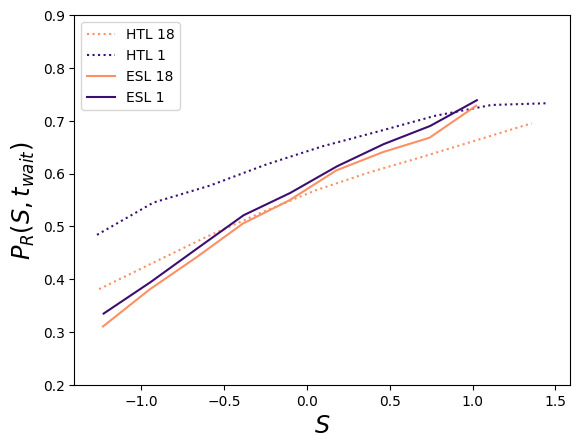

In [162]:
plot_out = defaultdict(list)

cmap = plt.get_cmap("magma")
norm = colors.Normalize(vmin=-5, vmax=25)

for key, val in output.items():
    if key.max_shear != 0.03:
        continue

    df = pd.concat(val)
    # pr = pearsonr(np.log(df["f512"]), np.log(df["d2min_rev"]))
    # bins f512 and get rearrangement probability as a function of bin
    logf = df["soft"]
    # logf = df["soft"]
    q5 = np.quantile(logf, 0.01)
    q95 = np.quantile(logf, 0.99)
    bins = np.linspace(q5, q95, 10)
    df["bins"] = pd.cut(logf, bins)

    vals = []
    for bin, tdf in df.groupby("bins"):
        prob_rearrange = np.mean(tdf["d2min_rev"] > 0.08)
        
        # plt.plot(bin.mid, prob_rearrange, marker=m,
        # color=cmap(norm(key.max_shear)))
        vals.append((bin.mid, prob_rearrange))

    prep = key.prep
    if prep == "GQ":
        prep = "ESL"
        ls = "-"
    else:
        ls = ":"

    vals = sorted(vals, key=lambda x: x[0])

    x, y = zip(*vals)
    plt.plot(x, y, ls=ls, color=cmap(norm(key.cycle)), label=f"{prep} {key.cycle}")

plt.legend()
    
#     plot_out[Plot(prep=key.prep, cycle=key.cycle)].append((key.max_shear, pr[0]))
#     # plt.plot(key.max_shear, pr[0], marker=m, color=c)

# for key, val in plot_out.items():
#     if key.prep == "GQ":
#         m = "D"
        
#     else:
#         m = "s"
#         # ls = ":"
#     ls = "-"

#     if key.cycle == 1:
#         c = "red"
#     else:
#         c = "blue"

#     val = sorted(val, key=lambda x: x[0])
#     x, y = zip(*val)
#     plt.plot(x, y, marker=m, color=c, ls=ls)
plt.ylim(.2, .9)

plt.ylabel(r"$P_R(S, t_{wait})$", size="xx-large")
plt.xlabel(r'$S$', size="xx-large")
plt.savefig("tmp2.png", dpi=200)